In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [4]:
observables = ['evid','xsec','pt','n','parton','nch','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m']

In [5]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_default_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_default_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_default_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_default_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_default_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_default_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_default_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_default_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_default_50pthat1000_rc_truth.txt']

In [6]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [7]:
df = applyCut(df, 'pt>20')

In [8]:
print('number of jets with q1 == -1:', df[df.q1==-1].shape[0])
print('number of jets with q1 == +1:', df[df.q1==1].shape[0])

number of jets with q1 == -1: 742166
number of jets with q1 == +1: 971611


In [9]:
diquark_array = np.array([1103,2101,2103,2203,3101,3103,3201,3203,3303,4101,4103,4201,4203,4301,4303,4403,5101,5103,5201,\
                          5203,5301,5303,5401,5403,5503])

In [10]:
parent1_new = []
parent2_new = []
for i in range(0, df.shape[0]):
    parent1 = df.iloc[i]['parent1']
    parent2 = df.iloc[i]['parent2']
    if (parent1 in diquark_array):
        parent1_new.append(-998)
    else:
        parent1_new.append(parent1)
    if (parent2 in diquark_array):
        parent2_new.append(-998)
    else:
        parent2_new.append(parent2)

In [11]:
df['parent1_new'] = parent1_new
df['parent2_new'] = parent2_new

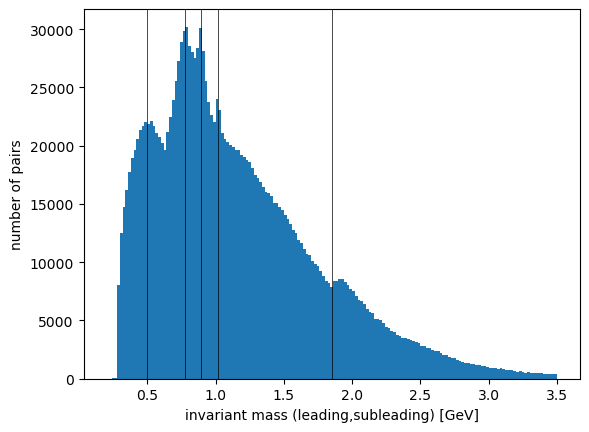

In [12]:
plt.hist(df['m'], bins=np.arange(0.2, 3.52, 0.02))
plt.xlabel('invariant mass (leading,subleading) [GeV]')
plt.ylabel('number of pairs')
plt.axvline(0.498, color='k', linewidth=0.5) # K0L,K0S? pid==130,310
plt.axvline(0.775, color='k', linewidth=0.5) # rho, found
plt.axvline(0.892, color='k', linewidth=0.5) # K*, found
plt.axvline(1.019, color='k', linewidth=0.5) # phi, pid==333
plt.axvline(1.850, color='k', linewidth=0.5) # ???

In [13]:
print(sum(df[(df.parent1_new!=-999) & (df.parent1_new!=-998)]['w'])/sum(df['w']))
print(sum(df[(df.parent2_new!=-999) & (df.parent2_new!=-998)]['w'])/sum(df['w']))

0.4656968310866072
0.5415122300377244


In [14]:
unique_parent1_new_array = np.unique(df['parent1_new'])
unique_parent2_new_array = np.unique(df['parent2_new'])

In [15]:
print(unique_parent1_new_array)

[ -20423  -20413  -20313  -20213  -10423  -10421  -10413  -10411  -10323
  -10321  -10313  -10311   -5232   -5132   -5122   -4332   -4232   -4224
   -4132   -4122   -4114   -3324   -3314   -3224   -3214   -3114   -2224
   -2214   -2114   -1114    -999    -998    -531    -521    -511    -431
    -425    -421    -415    -413    -411    -325    -323    -315    -313
    -215    -213     -15     -13     -11      11      13      15     113
     213     223     225     313     315     323     325     331     333
     411     413     415     421     425     431     435     441     443
     445     511     521     531    1114    2114    2214    2224    3114
    3214    3224    3314    3324    4112    4122    4132    4224    4232
    4332    5122    5132    5232   10221   10311   10313   10321   10323
   10413   10421   10441   20213   20313   20413   20423   20443  100441
  100443 9000221 9010221]


In [16]:
print(unique_parent2_new_array)

[-9000211   -20423   -20413   -20313   -20213   -10423   -10421   -10413
   -10411   -10323   -10321   -10313   -10311    -5232    -5224    -5132
    -5122    -5112    -4332    -4232    -4224    -4222    -4132    -4124
    -4122    -4114    -4112    -3324    -3314    -3224    -3214    -3114
    -2224    -2214    -2114    -1114     -999     -998     -531     -521
     -511     -431     -425     -421     -415     -413     -411     -325
     -323     -315     -313     -213      -15      -13      -11       11
       13       15      113      213      223      225      313      315
      323      325      331      333      411      413      415      421
      425      431      441      443      445      511      521      531
     1114     2114     2214     2224     3114     3214     3224     3314
     3324     4112     4114     4122     4132     4222     4224     4232
     4332     5114     5122     5132     5222     5224     5232    10221
    10311    10313    10321    10323    10411    10

# List parent PIDs and probabilities

## Leading

In [17]:
pid_array = []
prob_array = []
df_211 = applyCut(df, 'pid1==211')
prob_tot = 0
print('leading track pid: 211')
for unique_parent1 in unique_parent1_new_array:
    prob = sum(df_211[df_211.parent1_new==unique_parent1]['w'])/sum(df_211['w'])
    if (prob > 0.0):
        print('leading track parent pid:', unique_parent1, ', probability:', prob)
    pid_array.append(str(unique_parent1))
    #prob_array.append([prob])
    prob_array.append(prob)
    prob_tot += prob

leading track pid: 211
leading track parent pid: -20423 , probability: 3.82812858714452e-09
leading track parent pid: -20313 , probability: 7.344877301549826e-05
leading track parent pid: -10423 , probability: 1.3468782740245712e-07
leading track parent pid: -10421 , probability: 2.9319707666112923e-08
leading track parent pid: -10313 , probability: 7.257619401135935e-07
leading track parent pid: -10311 , probability: 4.271681831721408e-05
leading track parent pid: -5232 , probability: 1.5499968442100813e-05
leading track parent pid: -5132 , probability: 3.601887243393829e-08
leading track parent pid: -5122 , probability: 4.397553166938957e-05
leading track parent pid: -4122 , probability: 5.4043228344470066e-05
leading track parent pid: -4114 , probability: 1.4132429559138072e-06
leading track parent pid: -3314 , probability: 1.0321714162805113e-05
leading track parent pid: -3114 , probability: 0.0006059126396698116
leading track parent pid: -2114 , probability: 0.00017620871938412133

In [18]:
pid_array = []
prob_array = []
df_2212 = applyCut(df, 'pid1==2212')
prob_tot = 0
print('leading track pid: 2212')
for unique_parent1 in unique_parent1_new_array:
    prob = sum(df_2212[df_2212.parent1_new==unique_parent1]['w'])/sum(df_2212['w'])
    if (prob > 0.01):
        print('leading track parent pid:', unique_parent1, ', probability:', prob)
    pid_array.append(str(unique_parent1))
    #prob_array.append([prob])
    prob_array.append(prob)
    prob_tot += prob

leading track pid: 2212
leading track parent pid: -999 , probability: 0.41113437660287594
leading track parent pid: -998 , probability: 0.272954100568529
leading track parent pid: 2114 , probability: 0.058119277994638265
leading track parent pid: 2214 , probability: 0.10269973257239476
leading track parent pid: 2224 , probability: 0.15147242613232562


## Subleading

In [77]:
pid_array = []
prob_array = []
df_211 = applyCut(df, 'pid2==211')
print('subleading track pid: 211')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_211[df_211.parent2_new==unique_parent2_new]['w'])/sum(df_211['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 211
subleading track parent pid: -999 , probability: 0.25161668764948747
subleading track parent pid: -998 , probability: 0.14672593774838083
subleading track parent pid: -313 , probability: 0.024148043051232165
subleading track parent pid: 113 , probability: 0.17696731325970666
subleading track parent pid: 213 , probability: 0.19451440945832674
subleading track parent pid: 223 , probability: 0.13470151638923636
subleading track parent pid: 323 , probability: 0.031237633030547454


In [ ]:
# 113: rho0, 213: rho+, 223: omega, 313: K*0, 323: K*+

In [16]:
pid_array = []
prob_array = []
df_n211 = applyCut(df, 'pid2==-211')
print('subleading track pid: -211')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_n211[df_n211.parent2_new==unique_parent2_new]['w'])/sum(df_n211['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -211
subleading track parent pid: -999 , probability: 0.24147275647428224
subleading track parent pid: -998 , probability: 0.14722143454548045
subleading track parent pid: -323 , probability: 0.027278457953087424
subleading track parent pid: -213 , probability: 0.18627244821881256
subleading track parent pid: 113 , probability: 0.18577980308187753
subleading track parent pid: 223 , probability: 0.14158476736682013
subleading track parent pid: 313 , probability: 0.026766813768178858
subleading track parent pid: 1114 , probability: 0.013333205111929687


In [17]:
pid_array = []
prob_array = []
df_321 = applyCut(df, 'pid2==321')
print('subleading track pid: 321')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_321[df_321.parent2_new==unique_parent2_new]['w'])/sum(df_321['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 321
subleading track parent pid: -999 , probability: 0.3876876717350746
subleading track parent pid: -998 , probability: 0.2153492192382411
subleading track parent pid: -421 , probability: 0.01619352557714734
subleading track parent pid: 313 , probability: 0.22212138830225828
subleading track parent pid: 323 , probability: 0.11037471371993426
subleading track parent pid: 333 , probability: 0.0381044169829347


In [ ]:
# 313: K*0, 323: K*+, 333: phi, 421: D0

In [18]:
pid_array = []
prob_array = []
df_n321 = applyCut(df, 'pid2==-321')
print('subleading track pid: -321')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_n321[df_n321.parent2_new==unique_parent2_new]['w'])/sum(df_n321['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -321
subleading track parent pid: -999 , probability: 0.3756715574244826
subleading track parent pid: -998 , probability: 0.234211708685846
subleading track parent pid: -323 , probability: 0.11841525224691274
subleading track parent pid: -313 , probability: 0.199652044047358
subleading track parent pid: 333 , probability: 0.0378121677119248
subleading track parent pid: 421 , probability: 0.022123577623374385


In [19]:
pid_array = []
prob_array = []
df_2212 = applyCut(df, 'pid2==2212')
print('subleading track pid: 2212')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_2212[df_2212.parent2_new==unique_parent2_new]['w'])/sum(df_2212['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 2212
subleading track parent pid: -999 , probability: 0.37161057098431166
subleading track parent pid: -998 , probability: 0.2847724053868672
subleading track parent pid: 2114 , probability: 0.05380957374041166
subleading track parent pid: 2214 , probability: 0.10632731633392441
subleading track parent pid: 2224 , probability: 0.18170181741193736


In [48]:
# 2114: Delta0, 2214: Delta+, 2224: Delta++

In [19]:
pid_array = []
prob_array = []
df_n2212 = applyCut(df, 'pid2==-2212')
print('subleading track pid: -2212')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_n2212[df_n2212.parent2_new==unique_parent2_new]['w'])/sum(df_n2212['w'])
    if (prob > 0.0):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -2212
subleading track parent pid: -5122 , probability: 3.404241195995012e-05
subleading track parent pid: -4122 , probability: 0.00045521007871398363
subleading track parent pid: -2224 , probability: 0.14745399461406583
subleading track parent pid: -2214 , probability: 0.10160403596014769
subleading track parent pid: -2114 , probability: 0.0542927080828379
subleading track parent pid: -999 , probability: 0.43870340942594604
subleading track parent pid: -998 , probability: 0.25689766911240175
subleading track parent pid: -531 , probability: 5.591789130477944e-05
subleading track parent pid: -521 , probability: 2.4466917162202538e-05
subleading track parent pid: -511 , probability: 6.510406442093544e-05
subleading track parent pid: 441 , probability: 6.554873374397536e-08
subleading track parent pid: 443 , probability: 6.554873374397536e-08
subleading track parent pid: 445 , probability: 2.735151427326644e-05
subleading track parent pid: 511 , probability: 0.000190

# Assign specific codes to sign preserving decays

In [21]:
parent1_new = []
parent2_new = []
for i in range(0, df.shape[0]):
    parent1 = df.iloc[i]['parent1_new']
    parent2 = df.iloc[i]['parent2_new']
    pid1 = df.iloc[i]['pid1']
    pid2 = df.iloc[i]['pid2']
    if ((abs(pid1) == 211 or abs(pid1) == 321) and (abs(parent1) == 213 or abs(parent1) == 323)): # sign preserving decay
        parent1_new.append(-997)
    elif (abs(pid1) == 2212 and (abs(parent1) == 2214 or abs(parent1) == 2224)):
        parent1_new.append(-997)
    else:
        parent1_new.append(parent1)
    if ((abs(pid2) == 211 or abs(pid2) == 321) and (abs(parent2) == 213 or abs(parent2) == 323)): # sign preserving decay
        parent2_new.append(-997)
    elif (abs(pid2) == 2212 and (abs(parent2) == 2214 or abs(parent2) == 2224)):
        parent2_new.append(-997)
    else:
        parent2_new.append(parent2)

In [22]:
df['parent1_new'] = parent1_new
df['parent2_new'] = parent2_new

In [23]:
print(sum(df[(df.parent1_new!=-999) & (df.parent1_new!=-998) & (df.parent1_new!=-997)]['w'])/sum(df['w']))
print(sum(df[(df.parent2_new!=-999) & (df.parent2_new!=-998) & (df.parent2_new!=-997)]['w'])/sum(df['w']))

0.2629571602065858
0.3379208329640588


In [24]:
df.eval('b_ch = q1*q2', inplace=True)
df_signal = applyCut(df, '-999<=parent1_new<=-997 and -999<=parent2_new<=-997')
#df_nondecay = applyCut(df, 'parent1==-999 and parent2==-999')
#df_samesigndecay = applyCut(df, 'parent1==-997 and parent2==-997')
df_onedecay = applyCut(df, '(-999<=parent1_new<=-997 and (parent2_new<-999 or parent2_new>-997)) or\
                            (-999<=parent2_new<=-997 and (parent1_new<-999 or parent1_new>-997))')
df_twodecay = applyCut(df, '(parent1_new<-999 or parent1_new>-997) and (parent2_new<-999 or parent2_new>-997)')

In [25]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [26]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [27]:
df_signal_array = [ df_signal[(df_signal.pt>20) & (df_signal.pt<25)],\
            df_signal[(df_signal.pt>25) & (df_signal.pt<30)],\
            df_signal[(df_signal.pt>30) & (df_signal.pt<40)] ]

In [28]:
signal_rc_array = []
signal_rc_err_array = []
for i in range(0, len(df_signal_array)):
    signal_rc_array.append(getRcAndErr(df_signal_array[i], 'b_ch')[0])
    signal_rc_err_array.append(getRcAndErr(df_signal_array[i], 'b_ch')[1])

In [29]:
df_onedecay_array = [ df_onedecay[(df_onedecay.pt>20) & (df_onedecay.pt<25)],\
            df_onedecay[(df_onedecay.pt>25) & (df_onedecay.pt<30)],\
            df_onedecay[(df_onedecay.pt>30) & (df_onedecay.pt<40)] ]

In [30]:
onedecay_rc_array = []
onedecay_rc_err_array = []
for i in range(0, len(df_onedecay_array)):
    onedecay_rc_array.append(getRcAndErr(df_onedecay_array[i], 'b_ch')[0])
    onedecay_rc_err_array.append(getRcAndErr(df_onedecay_array[i], 'b_ch')[1])

In [31]:
df_twodecay_array = [ df_twodecay[(df_twodecay.pt>20) & (df_twodecay.pt<25)],\
            df_twodecay[(df_twodecay.pt>25) & (df_twodecay.pt<30)],\
            df_twodecay[(df_twodecay.pt>30) & (df_twodecay.pt<40)] ]

In [32]:
twodecay_rc_array = []
twodecay_rc_err_array = []
for i in range(0, len(df_twodecay_array)):
    twodecay_rc_array.append(getRcAndErr(df_twodecay_array[i], 'b_ch')[0])
    twodecay_rc_err_array.append(getRcAndErr(df_twodecay_array[i], 'b_ch')[1])

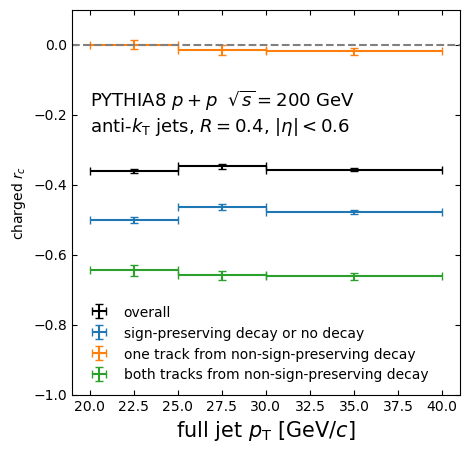

In [33]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_array, xerr=[2.5, 2.5, 5], yerr=rc_err_array, capsize=3, ls='none', label='overall', color='k')
plt.errorbar([22.5, 27.5, 35], signal_rc_array, xerr=[2.5, 2.5, 5], yerr=signal_rc_err_array, capsize=3, ls='none', label='sign-preserving decay or no decay')
plt.errorbar([22.5, 27.5, 35], onedecay_rc_array, xerr=[2.5, 2.5, 5], yerr=onedecay_rc_err_array, capsize=3, ls='none', label='one track from non-sign-preserving decay')
plt.errorbar([22.5, 27.5, 35], twodecay_rc_array, xerr=[2.5, 2.5, 5], yerr=twodecay_rc_err_array, capsize=3, ls='none', label='both tracks from non-sign-preserving decay')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.25,'PYTHIA8 $p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-1,0.1)
plt.legend(fontsize=10, loc='lower left', frameon=False)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')